# 6장 차원 축소 part A

**범위:** 6.1 차원 축소 개요 · 6.2 PCA · 6.3 LDA  

- `scikit-learn` 내장 데이터만 사용하므로 별도 파일은 필요하지 않습니다.
- 제공된 시작 코드를 바탕으로 `TODO` 부분을 완성해주세요. 필요한 라이브러리나 변수는 추가하셔도 됩니다.
- 각 문항의 해석 질문은 실행 결과를 근거로 **2~3문장**으로 작성해주세요.


## 문제 1. Wine 데이터: 정보를 얼마나 유지하며 차원을 줄일 수 있을까?

Wine 데이터에는 **178개 샘플, 13개 수치 피처, 3개 클래스**가 있습니다.

**(a)** 13개 피처를 표준화한 뒤 PCA를 적용하세요. **누적 설명된 분산 비율이 처음으로 90% 이상**이 되는 최소 주성분 개수를 계산하고, 그때의 누적 설명된 분산 비율을 출력하세요.  
**(b)** (a)에서 찾은 개수만큼 주성분을 남겨 변환하고, 결과 배열의 모양을 출력하세요.  
**(c)** 주성분 개수가 2개일 때의 누적 설명된 분산 비율도 계산한 다음, (a)의 결과와 비교하여 **주성분을 많이 남길수록 얻는 점과 잃는 점**을 설명하세요.

힌트: `explained_variance_ratio_`, `np.cumsum`, `np.argmax`, `PCA(n_components=...)`

In [1]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X, y = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

# TODO (a) 전체 주성분의 누적 설명된 분산 비율을 구하고 90% 기준 최소 차원 수를 출력하세요.
pca_full = PCA().fit(X_scaled)
cum_ratio = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = np.argmax(cum_ratio >= 0.90) + 1   # 처음으로 90% 이상이 되는 인덱스 + 1 = 주성분 개수
print('주성분별 누적 설명된 분산 비율:', np.round(cum_ratio, 4))
print('누적 90% 이상이 되는 최소 주성분 개수:', n_90)
print('그때의 누적 설명된 분산 비율: {0:.4f}'.format(cum_ratio[n_90 - 1]))

# TODO (b) 최소 차원 수로 PCA 변환하고 변환 후 데이터의 shape를 출력하세요.
pca_n = PCA(n_components=n_90)
X_pca_n = pca_n.fit_transform(X_scaled)
print('\n원본 데이터 shape:', X_scaled.shape)
print('PCA 변환 후 데이터 shape:', X_pca_n.shape)

# TODO (c) 주성분 2개의 누적 설명된 분산 비율을 출력하세요.
pca_2 = PCA(n_components=2).fit(X_scaled)
print('\n주성분 2개의 누적 설명된 분산 비율: {0:.4f}'.format(pca_2.explained_variance_ratio_.sum()))

주성분별 누적 설명된 분산 비율: [0.362  0.5541 0.6653 0.736  0.8016 0.851  0.8934 0.9202 0.9424 0.9617
 0.9791 0.992  1.    ]
누적 90% 이상이 되는 최소 주성분 개수: 8
그때의 누적 설명된 분산 비율: 0.9202

원본 데이터 shape: (178, 13)
PCA 변환 후 데이터 shape: (178, 8)

주성분 2개의 누적 설명된 분산 비율: 0.5541


**해석 답안:**

표준화한 Wine 데이터에 PCA를 적용하면 주성분 **8개**에서 누적 설명된 분산 비율이 처음으로 90%를 넘고(**약 92.0%**), 변환 후 데이터는 (178, 13)에서 **(178, 8)**이 된다. 반면 주성분을 2개만 남기면 누적 설명된 분산 비율이 **약 55.4%**에 그친다. 즉 주성분을 많이 남길수록 원본 데이터의 변동성(정보)을 더 많이 보존할 수 있지만, 그만큼 차원이 커져 시각화가 어렵고 계산량·과적합 위험이 다시 늘어나 차원 축소의 이점(압축, 해석 용이성)을 잃게 된다.

## 문제 2. 유방암 진단 데이터: PCA가 분류 성능에 미치는 영향

Breast Cancer Wisconsin 데이터에는 **569개 샘플, 30개 입력 피처, 2개 클래스**가 있습니다. 동일한 `LogisticRegression` 모델을 **원본 피처**와 **PCA로 5개 주성분으로 변환한 피처**에 각각 적용하려고 합니다.

**(a)** 원본 피처와 PCA 변환 피처에 대해 각각 `StandardScaler`가 포함된 `Pipeline`을 만들고, **5-Fold 층화 교차 검증**으로 평균 정확도를 구하세요. (두 모델 모두 동일한 `StratifiedKFold` 사용)  
**(b)** 두 모델의 평균 정확도 차이를 **퍼센트포인트(%p)** 단위로 출력하세요. (PCA 모델 − 원본 모델)  
**(c)** PCA 모델의 정확도가 낮아지거나 높아지더라도, **PCA가 반드시 분류 성능을 개선하는 방법은 아닌 이유**를 발표의 핵심 개념으로 설명하세요.

조건: `random_state=42`, `n_splits=5`, `shuffle=True`로 고정하세요. PCA는 **Pipeline 내부**에 배치합니다.

힌트: `make_pipeline`, `cross_val_score`, `StratifiedKFold`

In [2]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

X, y = load_breast_cancer(return_X_y=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# TODO (a) 원본 모델 파이프라인과 PCA(5개) 모델 파이프라인을 만들고
# 동일한 cv로 정확도를 비교하세요.
pipe_orig = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
pipe_pca = make_pipeline(StandardScaler(), PCA(n_components=5), LogisticRegression(max_iter=1000))

scores_orig = cross_val_score(pipe_orig, X, y, cv=cv, scoring='accuracy')
scores_pca = cross_val_score(pipe_pca, X, y, cv=cv, scoring='accuracy')

print('원본 모델 Fold별 정확도:', np.round(scores_orig, 4))
print('원본 모델 평균 정확도: {0:.4f}'.format(scores_orig.mean()))
print('PCA(5개) 모델 Fold별 정확도:', np.round(scores_pca, 4))
print('PCA(5개) 모델 평균 정확도: {0:.4f}'.format(scores_pca.mean()))

# TODO (b) 두 평균 정확도의 차이를 %p로 출력하세요.
diff = (scores_pca.mean() - scores_orig.mean()) * 100
print('\n정확도 차이 (PCA - 원본): {0:+.2f}%p'.format(diff))

원본 모델 Fold별 정확도: [0.9737 0.9474 0.9649 0.9912 0.9912]
원본 모델 평균 정확도: 0.9737
PCA(5개) 모델 Fold별 정확도: [0.9561 0.9474 0.9649 0.9561 0.9912]
PCA(5개) 모델 평균 정확도: 0.9631

정확도 차이 (PCA - 원본): -1.05%p


**해석 답안:**

5-Fold 층화 교차 검증 결과 원본 30개 피처 모델의 평균 정확도는 **약 97.37%**, PCA 5개 주성분 모델은 **약 96.31%**로, PCA 모델이 **약 1.05%p** 낮았다. PCA는 레이블을 전혀 보지 않는 비지도 기법으로, **클래스를 잘 구분하는 축이 아니라 입력 데이터의 분산이 가장 큰 축**을 찾기 때문에 분산은 작지만 분류에 중요한 정보가 버려질 수 있다. 따라서 PCA는 피처 수를 크게 줄이면서(30개 → 5개) 비슷한 성능을 유지하는 압축·효율화 수단이지, 분류 성능을 반드시 개선해 주는 방법은 아니다.

## 문제 3. Wine 데이터: PCA와 LDA의 차원을 줄이는 기준 비교

문제 1의 Wine 데이터를 활용해 **13차원 → 2차원**으로 축소한 뒤, PCA와 LDA 결과를 비교하세요.

**(a)** `train_test_split(test_size=0.3, stratify=y, random_state=42)`로 학습·평가 데이터를 분리하고, 학습 데이터로만 `StandardScaler`를 학습해 두 데이터에 적용하세요. 그다음 **PCA(2개)**와 **LDA(2개)**를 각각 학습 데이터로 학습하여 학습·평가 데이터를 변환하세요. 결과 배열의 모양을 출력하세요. LDA에는 클래스 레이블을 입력해야 합니다.  
**(b)** 각각의 2차원 학습 데이터에 `LogisticRegression`을 학습하고, 평가 데이터 정확도를 출력하세요.  
**(c)** 두 방법이 서로 다른 결과를 내는 이유를 **사용하는 레이블과 축을 선택하는 기준**이라는 두 관점에서 설명하세요. 정확도가 높게 나온 방법이 모든 데이터에서 우월하다고 단정할 수 있는지도 덧붙이세요.

힌트: `LinearDiscriminantAnalysis(n_components=2)`, `fit_transform(X_train_scaled, y_train)`, `accuracy_score`

In [3]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = load_wine(return_X_y=True)

# TODO (a) 데이터를 분할하고 학습 데이터 기준으로 표준화한 뒤,
# PCA 및 LDA로 각각 2차원 학습/평가 데이터를 만드세요.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

scaler = StandardScaler().fit(X_train)          # 학습 데이터로만 fit
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)  # PCA는 레이블 사용 X
X_test_pca = pca.transform(X_test_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)  # LDA는 레이블 필요
X_test_lda = lda.transform(X_test_scaled)

print('PCA 학습/평가 shape:', X_train_pca.shape, X_test_pca.shape)
print('LDA 학습/평가 shape:', X_train_lda.shape, X_test_lda.shape)

# TODO (b) 변환된 데이터에 각각 로지스틱 회귀 모델을 학습시켜 평가 정확도를 출력하세요.
lr_pca = LogisticRegression(max_iter=1000).fit(X_train_pca, y_train)
lr_lda = LogisticRegression(max_iter=1000).fit(X_train_lda, y_train)

acc_pca = accuracy_score(y_test, lr_pca.predict(X_test_pca))
acc_lda = accuracy_score(y_test, lr_lda.predict(X_test_lda))
print('\nPCA(2개) + 로지스틱 회귀 평가 정확도: {0:.4f}'.format(acc_pca))
print('LDA(2개) + 로지스틱 회귀 평가 정확도: {0:.4f}'.format(acc_lda))

PCA 학습/평가 shape: (124, 2) (54, 2)
LDA 학습/평가 shape: (124, 2) (54, 2)

PCA(2개) + 로지스틱 회귀 평가 정확도: 0.9444
LDA(2개) + 로지스틱 회귀 평가 정확도: 0.9815


**해석 답안:**

13차원을 2차원으로 축소했을 때 평가 정확도는 PCA가 **약 94.44%**, LDA가 **약 98.15%**로 LDA가 더 높았다. 레이블 관점에서 PCA는 클래스 레이블 없이 학습하는 비지도 기법이고 LDA는 `fit()`에 y_train을 넣는 지도 기법이며, 축 선택 기준 관점에서 PCA는 **입력 데이터의 분산이 최대인 축**을, LDA는 **클래스 간 분산은 크게·클래스 내부 분산은 작게** 만드는 축을 고르기 때문에 분류 문제에서는 LDA 축이 클래스를 더 잘 분리한다. 다만 이는 이 데이터(클래스가 선형적으로 잘 나뉘는 Wine)와 이번 분할에서의 결과일 뿐이며, 레이블이 없거나 클래스 분포가 선형 가정과 맞지 않는 데이터, 또는 데이터 구조 탐색·압축이 목적인 경우에는 PCA가 더 적합할 수 있어 LDA가 항상 우월하다고 단정할 수는 없다.

# **문제 4. SVD를 이용한 행렬 분해 및 복원**

## **4-1. 행렬 분해**

SVD를 이용하여 5x5 행렬 a를 분해 해주세요.

In [4]:
import numpy as np
from numpy.linalg import svd

np.random.seed(10)
a = np.random.randn(5, 5)

U, Sigma, Vt = svd(a)

print('Origianl matrix a:\n', np.round(a, 3))
print('\nU matrix:\n', np.round(U, 3))
print('\nSigma matrix:\n', np.round(Sigma, 3))
print('\nV transpose matrix:\n', np.round(Vt, 3))

Origianl matrix a:
 [[ 1.332  0.715 -1.545 -0.008  0.621]
 [-0.72   0.266  0.109  0.004 -0.175]
 [ 0.433  1.203 -0.965  1.028  0.229]
 [ 0.445 -1.137  0.135  1.485 -1.08 ]
 [-1.978 -1.743  0.266  2.385  1.124]]

U matrix:
 [[-0.34   0.653 -0.057  0.53   0.416]
 [ 0.06  -0.106 -0.18  -0.506  0.835]
 [-0.116  0.668 -0.086 -0.655 -0.322]
 [ 0.291  0.183  0.923 -0.065  0.161]
 [ 0.884  0.286 -0.325  0.174  0.008]]

Sigma matrix:
 [4.077 2.543 1.952 1.107 0.3  ]

V transpose matrix:
 [[-0.531 -0.549  0.225  0.595  0.106]
 [ 0.295  0.211 -0.615  0.643  0.276]
 [ 0.548 -0.346  0.097  0.259 -0.71 ]
 [ 0.373 -0.698 -0.185 -0.327  0.483]
 [-0.437 -0.218 -0.726 -0.242 -0.419]]


## **4-2. 행렬 복원**

분해한 행렬을 복원해 주세요.

In [5]:
# Sigma를 대각행렬로 변환
Sigma_mat = np.diag(Sigma)

# U, Sigma, Vt를 이용하여 원본 행렬 복원
a_ = np.dot(np.dot(U, Sigma_mat), Vt)

print(np.round(a_, 3))

[[ 1.332  0.715 -1.545 -0.008  0.621]
 [-0.72   0.266  0.109  0.004 -0.175]
 [ 0.433  1.203 -0.965  1.028  0.229]
 [ 0.445 -1.137  0.135  1.485 -1.08 ]
 [-1.978 -1.743  0.266  2.385  1.124]]


## **4-3. 위 코드에서 Sigma의 shape를 작성해 주세요.**

**(5,)**

`numpy.linalg.svd()`는 Sigma를 대각행렬이 아니라 **0이 아닌 특이값만 담은 1차원 배열**로 반환한다. 5×5 행렬이므로 특이값 5개가 담긴 shape (5,) 배열이 나오고, 복원할 때는 `np.diag(Sigma)`로 5×5 대각행렬로 바꿔서 내적한다.

# **문제 5. Truncated SVD를 이용한 차원 축소**
다음은 Wine 데이터셋에 Truncated SVD를 적용하여 13차원 데이터를 2차원으로 축소하는 코드입니다.

\## 답안 ## 에 알맞은 코드를 작성해 주세요.

## **5-1. 차원 축소**

2차원으로 축소해주세요.

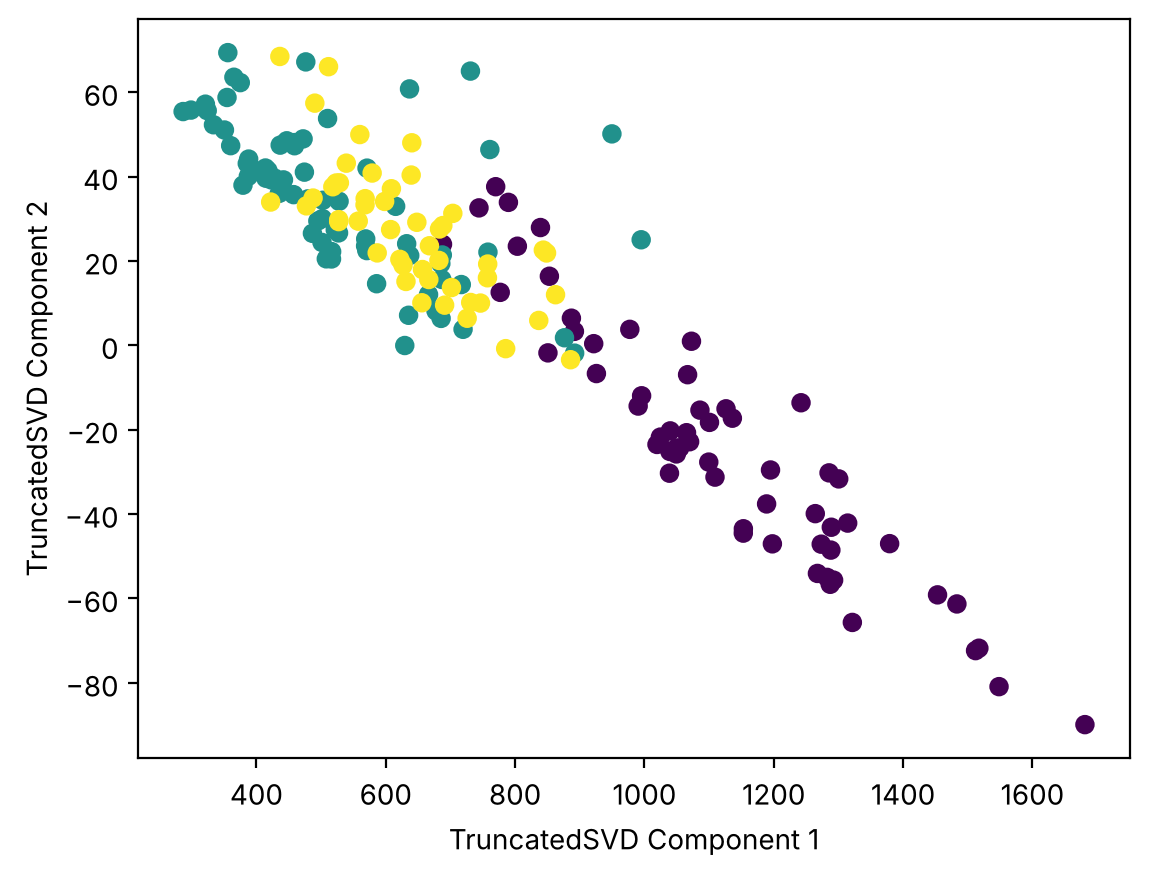

In [6]:
from sklearn.decomposition import TruncatedSVD
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
%matplotlib inline

wine = load_wine()
wine_ftrs = wine.data

tsvd = TruncatedSVD(n_components=2)

tsvd.fit(wine_ftrs)
wine_tsvd = tsvd.transform(wine_ftrs)

# 시각화
plt.scatter(
    x=wine_tsvd[:, 0],
    y=wine_tsvd[:, 1],
    c=wine.target
)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')
plt.show()

# **문제 6. SVD와 Truncated SVD 비교**

#### **SVD와 Truncated SVD의 차이점을 사용되는 특이값의 개수와 행렬 복원 시 정보 손실여부를 중심으로 서술해 주세요.**

- **사용하는 특이값의 개수:** 일반 SVD(Full/Compact)는 행렬 A의 **모든 특이값**과 그에 대응하는 U, V 벡터를 사용한다. 반면 Truncated SVD는 Σ의 대각원소 중 **값이 큰 상위 k개의 특이값만** 추출하고, 나머지 특이값과 그에 대응하는 U의 열·Vᵀ의 행은 제거한다.
- **행렬 복원 시 정보 손실 여부:** 일반 SVD는 U·Σ·Vᵀ를 내적하면 원본 행렬을 **정보 손실 없이 정확히 복원**할 수 있다. Truncated SVD는 일부 특이값을 버렸기 때문에 원본을 정확히 복원할 수 없고 **근사적으로만 복원(정보 손실 발생)**되며, 남기는 특이값 개수 k가 원래 차원에 가까울수록 원본에 더 가깝게 복원된다. 대신 더 작은 차원으로 데이터를 표현할 수 있어 차원 축소·잠재 요인 추출(LSA, 추천 시스템 등)에 활용된다.

## 다른 차원의 축소 기법들 개념 복습

# **문제 7.**  
 Discord에 공유된 핸즈온 머신러닝pdf의 '8.6 다른 차원축소 기법들(p. 295 ~ 296)' 혹은 Week10 발표 ppt 속 '#06 다른 차원의 축소 기법들' 파트 내용을 참고해서 랜덤 투영 알고리즘, MDS, ISomap, t-SNE 중 하나의 차원 축소 기법을 골라 간단히 설명하세요.

답 : **t-SNE (t-distributed Stochastic Neighbor Embedding)**

비슷한 샘플은 가까이, 비슷하지 않은 샘플은 멀리 떨어지도록 하면서 차원을 축소하는 기법이다. 고차원 공간에서 샘플 간 유사도를 확률로 나타낸 뒤, 저차원 공간에서도 이 유사도 분포가 최대한 비슷하게 유지되도록 데이터를 배치한다. 주로 **시각화**에 많이 사용되며, 특히 고차원 공간에 있는 샘플의 **군집을 시각화**할 때 유용하다.

## 여러가지 차원 축소 기법들 적용하기

# 문제 8. Dimensionality Reduction for Beginners
8-1)  `PCA`, `MDS`, `t-SNE`각각의 코드를 완성해 실행하세요.   
8-2) 세 기법의 차이를 간단히 서술하세요.

In [7]:
#데이터 로딩하기

%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.datasets import load_breast_cancer #Loading the full DataSet From Sklearn Library

# Breast cancer dataset
cancer = load_breast_cancer()
(X_canc, y_canc) = load_breast_cancer(return_X_y = True)

In [8]:
#시각화 함수 만들기

def plot_labelled_scatter(X, y, class_labels,s):
    num_labels = len(class_labels)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    marker_array = ['o', '^', '*']
    color_array = ['#FFFF00', '#00AAFF', '#000000', '#FF00AA']
    cmap_bold = ListedColormap(color_array)
    bnorm = BoundaryNorm(np.arange(0, num_labels + 1, 1), ncolors=num_labels)
    plt.figure(figsize=s)

    plt.scatter(X[:, 0], X[:, 1], s=80, c=y, cmap=cmap_bold, norm = bnorm, alpha = 0.4, edgecolor='black', lw = 1)
    sp = plt.gca().spines
    sp['top'].set_visible(False)
    sp['right'].set_visible(False)

    plt.grid(which='both',color='lightslategrey',alpha=0.3)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    h = []
    for c in range(0, num_labels):
        h.append(mpatches.Patch(color=color_array[c], label=class_labels[c]))
    plt.legend(handles=h,fontsize=15,frameon=False)

8-1) `PCA`, `MDS`, `t-SNE` 코드 완성하기

PCA 코드 완성하기

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

canc_norm = StandardScaler().fit(X_canc).transform(X_canc)

pca = PCA(n_components = 2).fit(canc_norm)

canc_pca = pca.transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before PCA : {}\n\nNumber of Features in Breast Cancer DataSet After PCA : {}'
      .format(X_canc.shape[1], canc_pca.shape[1]))

Number of Features in Breat Cancer DataSet Before PCA : 30

Number of Features in Breast Cancer DataSet After PCA : 2


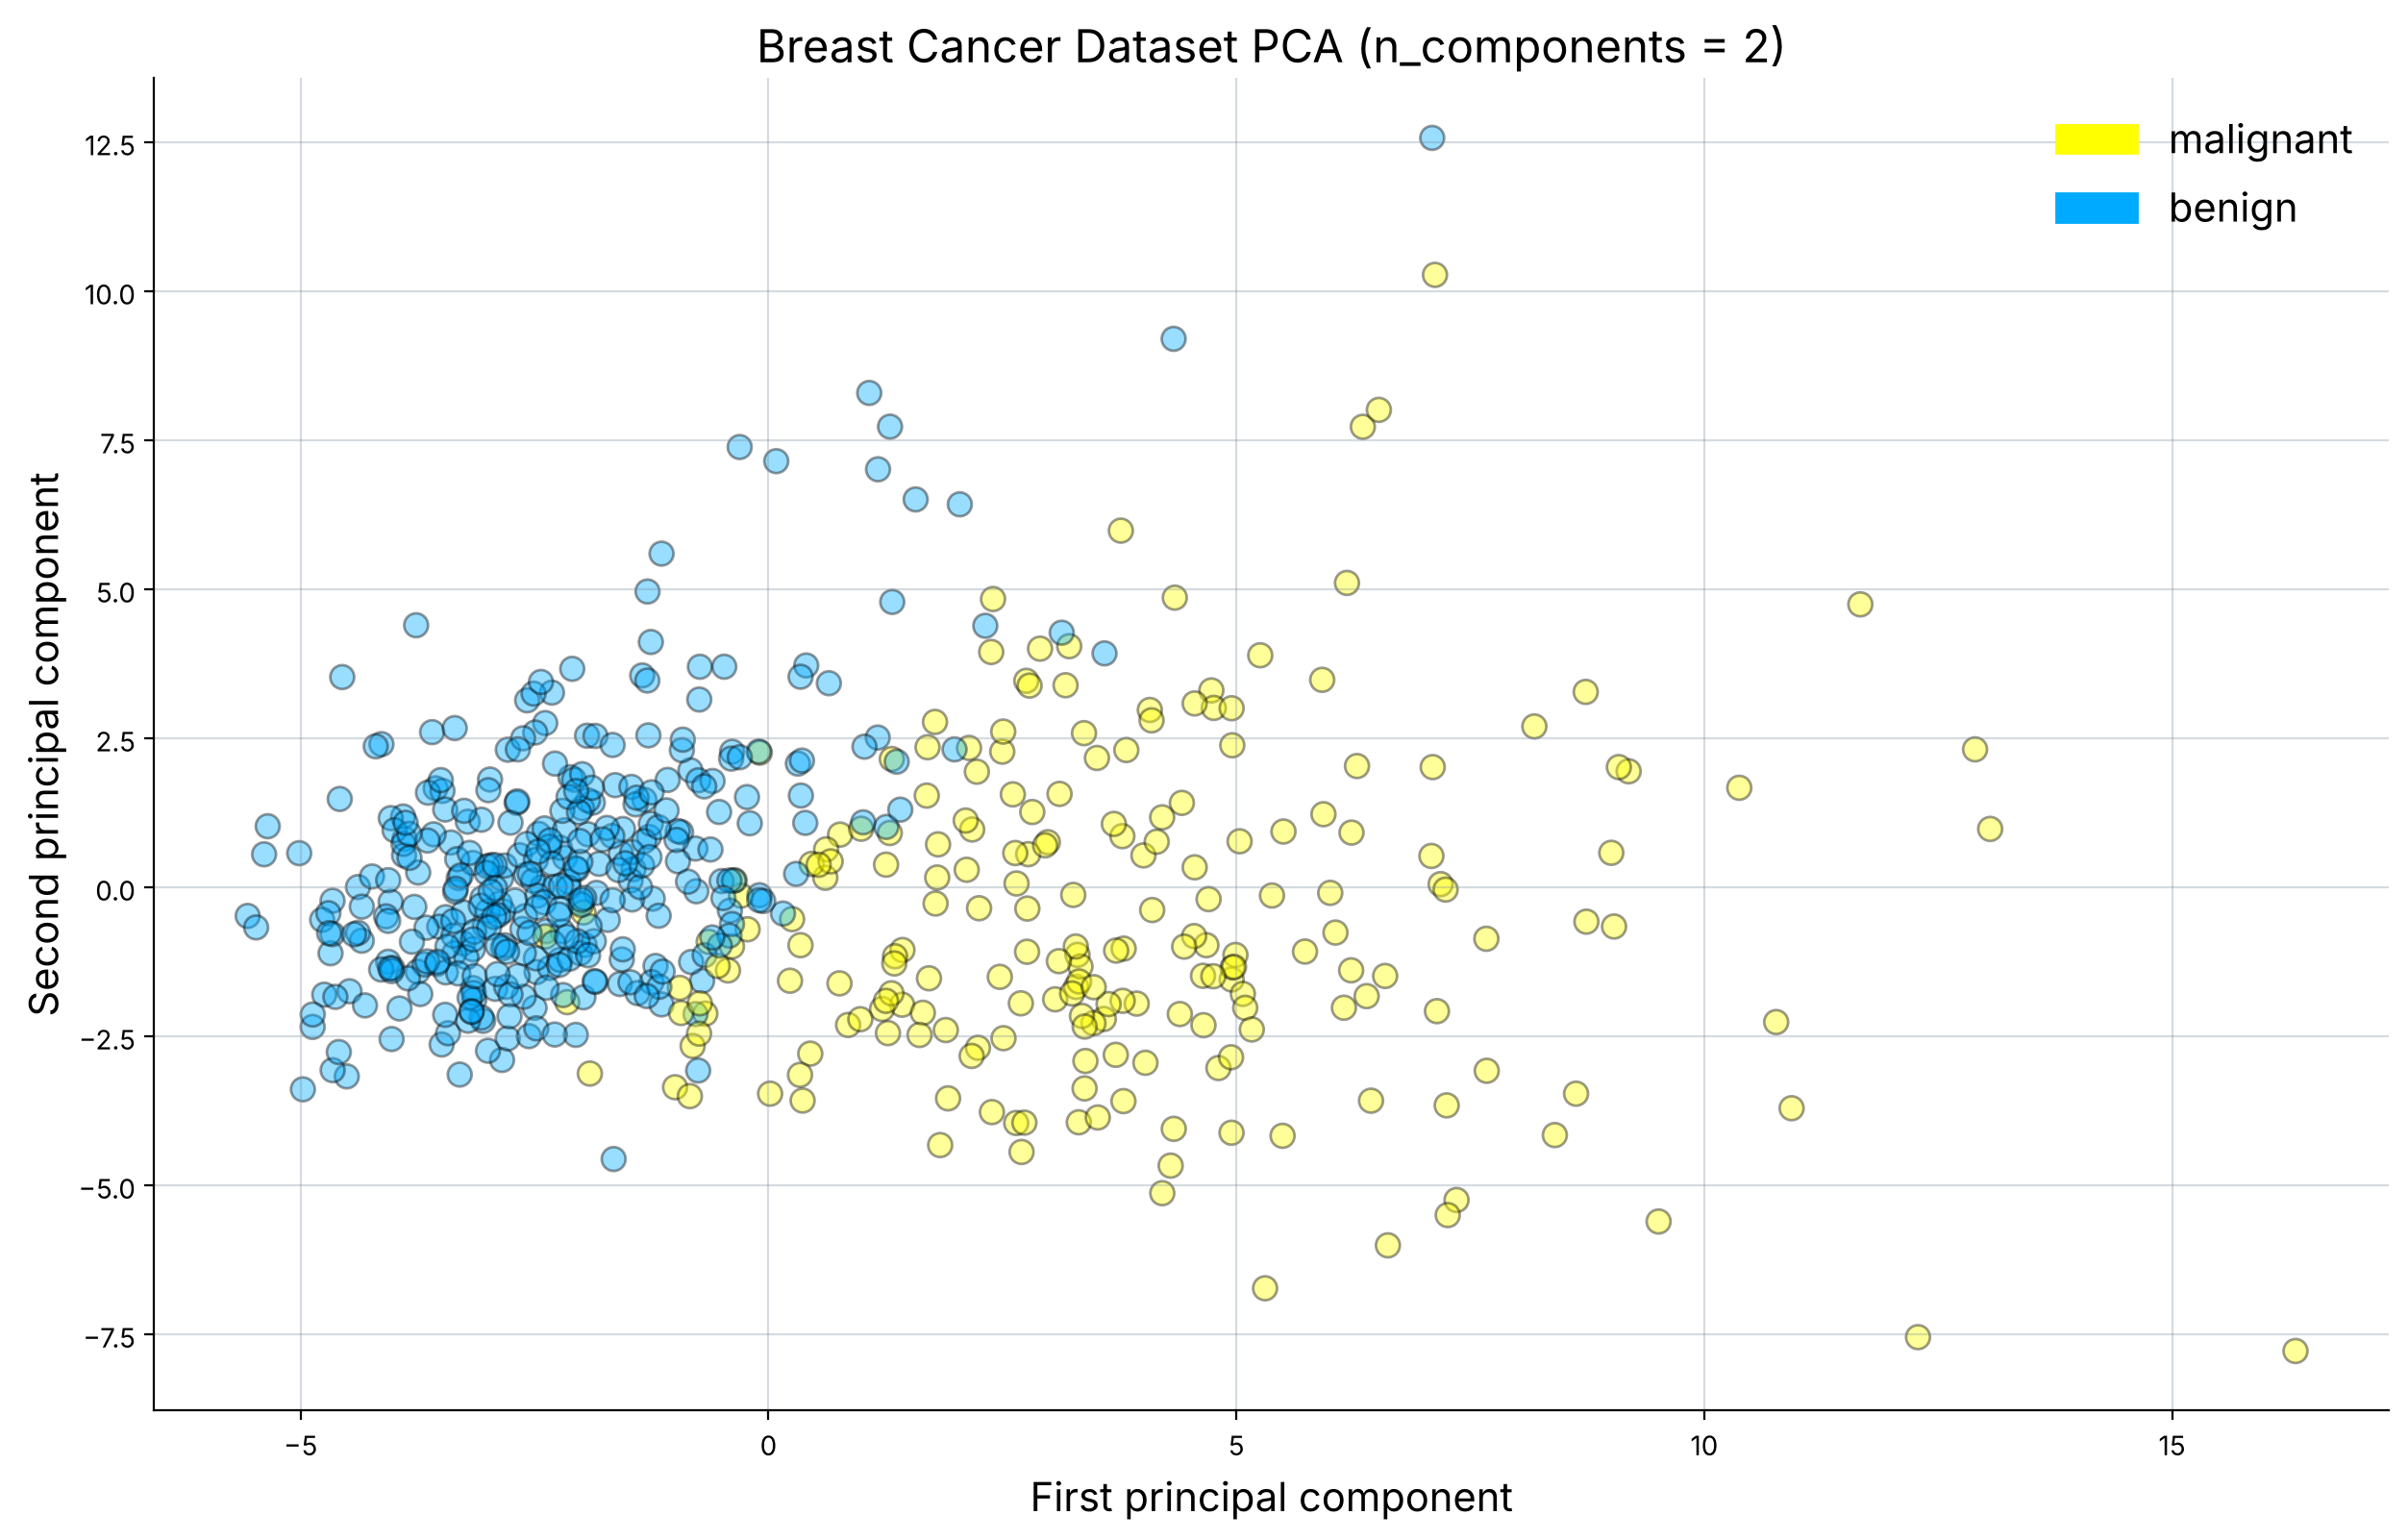

In [10]:
#앞서 만든 함수 사용
plot_labelled_scatter(canc_pca, y_canc, ['malignant', 'benign'],(15,9))

#Labelling
plt.xlabel('First principal component',fontsize=15)
plt.ylabel('Second principal component',fontsize=15)
plt.title('Breast Cancer Dataset PCA (n_components = 2)',fontsize=17);

MSD 코드 완성하기

/usr/local/lib/python3.13/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


Number of Features in Breat Cancer DataSet Before MDS : 30

Number of Features in Breast Cancer DataSet After MDS : 2


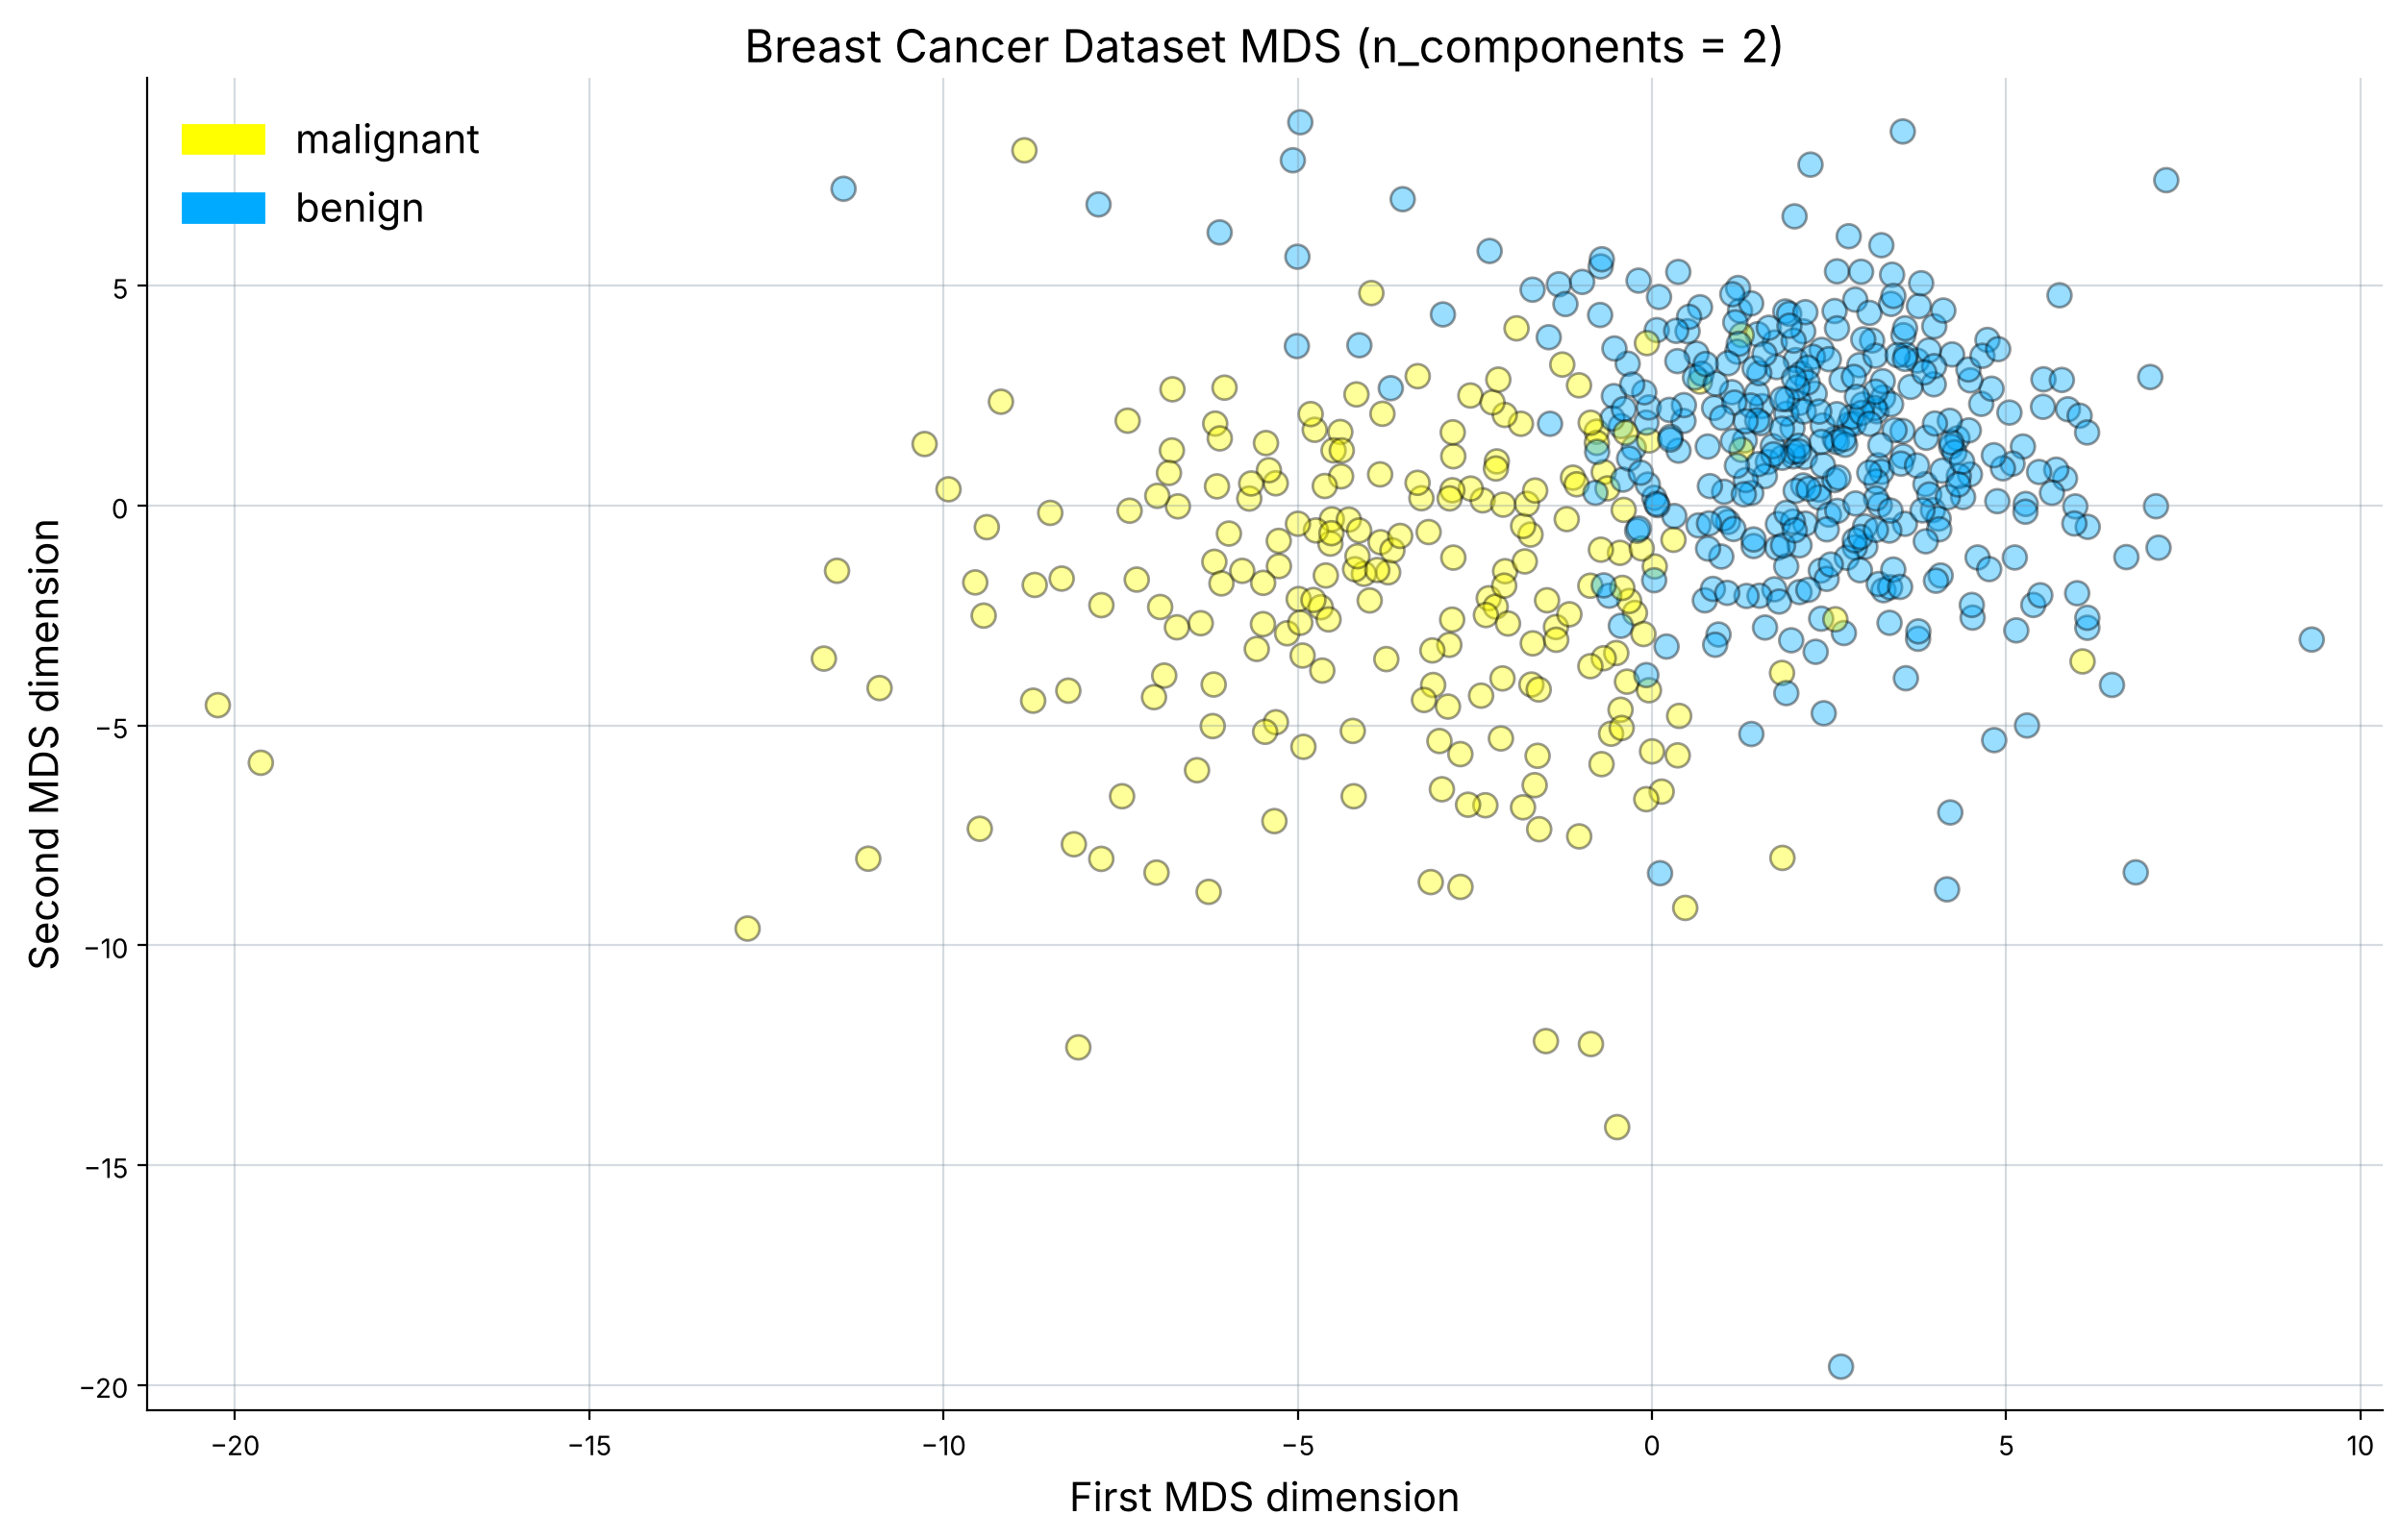

In [11]:
from sklearn.manifold import MDS

mds = MDS(n_components = 2, random_state = 2)      #이때 n_components = 2,random_state = 2로 두기

canc_mds = mds.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before MDS : {}\n\nNumber of Features in Breast Cancer DataSet After MDS : {}'
      .format(X_canc.shape[1],canc_mds.shape[1]))

plot_labelled_scatter(canc_mds, y_canc, ['malignant', 'benign'],(15,9))

plt.xlabel('First MDS dimension',fontsize=15)
plt.ylabel('Second MDS dimension',fontsize=15)
plt.title('Breast Cancer Dataset MDS (n_components = 2)',fontsize=17);

t-SNE 코드 완성하기

Number of Features in Breat Cancer DataSet Before T-SNE : 30

Number of Features in Breast Cancer DataSet After T-SNE : 2


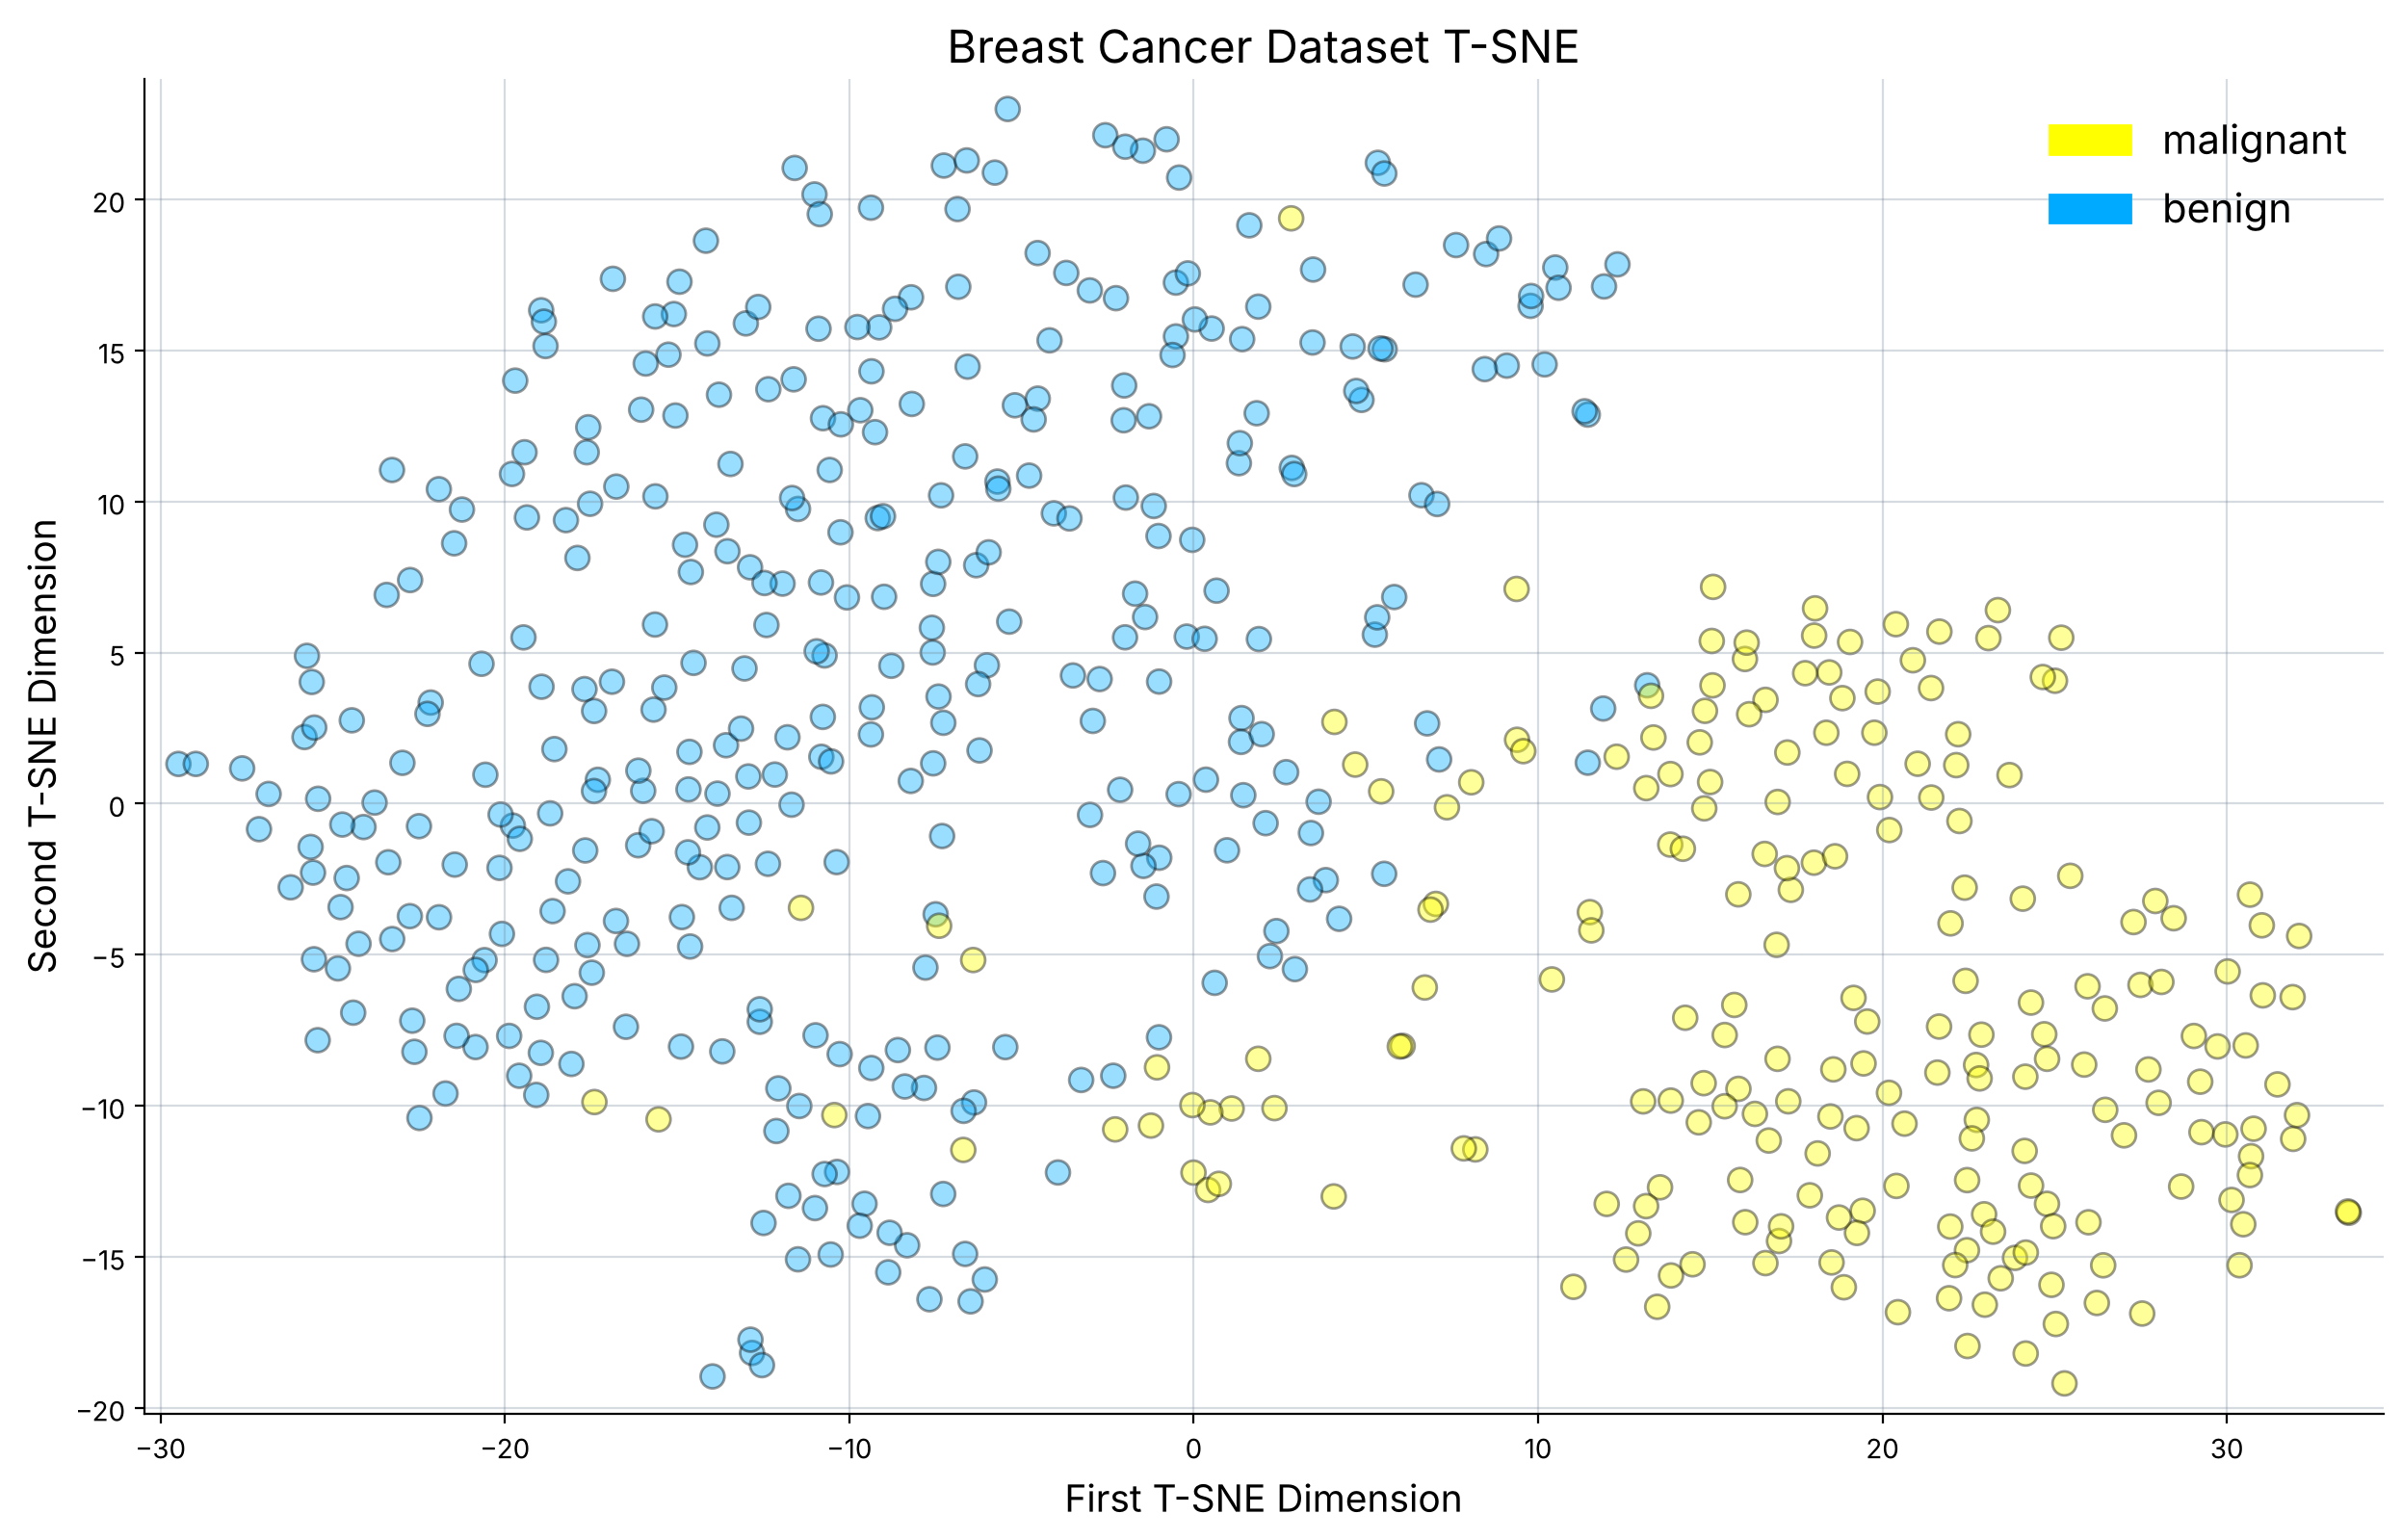

In [12]:
from sklearn.manifold import TSNE

tsne = TSNE(random_state = 42)     #이때 random_state = 42로 두기

canc_tsne = tsne.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before T-SNE : {}\n\nNumber of Features in Breast Cancer DataSet After T-SNE : {}'
      .format(X_canc.shape[1],canc_tsne.shape[1]))

plot_labelled_scatter(canc_tsne, y_canc, ['malignant', 'benign'],(15,9))

plt.xlabel('First T-SNE Dimension',fontsize=14)
plt.ylabel('Second T-SNE Dimension',fontsize=14)
plt.title('Breast Cancer Dataset T-SNE',fontsize=17);

8-2) 세 기법의 차이를 간단히 서술하세요.

답 :

- **PCA:** 데이터의 **분산이 가장 큰 방향(주성분)**으로 선형 투영하는 **선형** 기법이다. 계산이 빠르고 주성분 축이 원본 피처의 선형 결합이라 해석이 가능하며, 학습한 축으로 새 데이터도 `transform()`할 수 있다. 다만 비선형 구조는 잘 표현하지 못한다.
- **MDS(다차원 스케일링):** 샘플 간의 **거리를 최대한 보존**하면서 차원을 축소한다. 전체 샘플 쌍의 거리를 고려하므로 데이터가 많아지면 계산이 느려지고, 새 데이터에 바로 적용하는 `transform()`이 없다.
- **t-SNE:** 샘플 간 유사도를 확률로 바꿔 **가까운 이웃 관계(국소 구조)를 보존**하는 **비선형** 기법이다. 그래서 세 결과 중 악성/양성 군집이 가장 뚜렷하게 분리돼 보였지만, 축 자체에는 의미가 없고 군집 간 거리·크기를 그대로 해석하기 어려우며 주로 시각화 용도로 쓰인다.